In [1]:
from google.colab import files

uploaded = files.upload()

Saving spotify-tracks-dataset-detailed.csv to spotify-tracks-dataset-detailed.csv


In [2]:
import pandas as pd

df = pd.read_csv('spotify-tracks-dataset-detailed.csv')

print(df)

                      track_id                 artists  \
0       5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1       4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2       1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3       6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4       5vjLSffimiIP26QG5WcN2K        Chord Overstreet   
...                        ...                     ...   
113995  2C3TZjDRiAzdyViavDJ217           Rainy Lullaby   
113996  1hIz5L4IB9hN3WRYPOCGPw           Rainy Lullaby   
113997  6x8ZfSoqDjuNa5SVP5QjvX           Cesária Evora   
113998  2e6sXL2bYv4bSz6VTdnfLs        Michael W. Smith   
113999  2hETkH7cOfqmz3LqZDHZf5           Cesária Evora   

                                               album_name  \
0                                                  Comedy   
1                                        Ghost (Acoustic)   
2                                          To Begin Again   
3       Crazy Rich Asians (Original Motion Picture Sou...  

In [3]:
print(df.head())

                 track_id                 artists  \
0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   
3  Can't Help Falling In Love          71       201933     False   
4   

In [4]:
print(df.shape)

(114000, 20)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           11

In [6]:
print(df.isnull().sum())

track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [7]:
print("Total missing values:", df.isnull().sum().sum())


Total missing values: 3


In [11]:
import numpy as np



In [13]:
print("Numerical columns:")
print(df.select_dtypes(include=np.number).columns)



Numerical columns:
Index(['popularity', 'duration_ms', 'danceability', 'energy', 'key',
       'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness',
       'liveness', 'valence', 'tempo', 'time_signature'],
      dtype='object')


In [14]:


print("\nCategorical columns:")
print(df.select_dtypes(include='object').columns)


Categorical columns:
Index(['track_id', 'artists', 'album_name', 'track_name', 'track_genre'], dtype='object')


In [15]:
df['artists'].fillna('Unknown', inplace=True)

df['album_name'].fillna('Unknown', inplace=True)

df['track_name'].fillna('Unknown', inplace=True)

/tmp/ipykernel_2054/3048365103.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['artists'].fillna('Unknown', inplace=True)
/tmp/ipykernel_2054/3048365103.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usi

In [16]:
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].mean())

In [17]:
print(df.isnull().sum())

track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64


In [18]:
df['duration_minutes'] = df['duration_ms'] / 60000


In [19]:

print(df[['track_name', 'duration_ms', 'duration_minutes']].head())

                   track_name  duration_ms  duration_minutes
0                      Comedy       230666          3.844433
1            Ghost - Acoustic       149610          2.493500
2              To Begin Again       210826          3.513767
3  Can't Help Falling In Love       201933          3.365550
4                     Hold On       198853          3.314217


In [20]:
df.drop('track_id', axis=1, inplace=True)

In [21]:
print(df.shape)
print(df.head())

(114000, 20)
                  artists                                         album_name  \
0             Gen Hoshino                                             Comedy   
1            Ben Woodward                                   Ghost (Acoustic)   
2  Ingrid Michaelson;ZAYN                                     To Begin Again   
3            Kina Grannis  Crazy Rich Asians (Original Motion Picture Sou...   
4        Chord Overstreet                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   
3  Can't Help Falling In Love          71       201933     False   
4                     Hold On          82       198853     False   

   danceability  energy  key  loudness  mode  speechiness  acousticness  \
0         0.676  0.461

In [22]:
def popularity_category(value):
    if value < 40:
        return 'Low'
    elif value < 70:
        return 'Medium'
    else:
        return 'High'

df['popularity_level'] = df['popularity'].apply(popularity_category)

In [23]:
print(df[['track_name', 'popularity', 'popularity_level']].head(10))

                   track_name  popularity popularity_level
0                      Comedy          73             High
1            Ghost - Acoustic          55           Medium
2              To Begin Again          57           Medium
3  Can't Help Falling In Love          71             High
4                     Hold On          82             High
5        Days I Will Remember          58           Medium
6               Say Something          74             High
7                   I'm Yours          80             High
8                       Lucky          74             High
9                      Hunger          56           Medium


In [24]:
top_songs = df.sort_values(
    by='popularity',
    ascending=False
)

print(top_songs[['track_name', 'artists', 'popularity']].head(10))

                                  track_name                  artists  \
81051              Unholy (feat. Kim Petras)     Sam Smith;Kim Petras   
20001              Unholy (feat. Kim Petras)     Sam Smith;Kim Petras   
51664  Quevedo: Bzrp Music Sessions, Vol. 52         Bizarrap;Quevedo   
89411                             La Bachata            Manuel Turizo   
30003                        I'm Good (Blue)  David Guetta;Bebe Rexha   
20008                        I'm Good (Blue)  David Guetta;Bebe Rexha   
81210                        I'm Good (Blue)  David Guetta;Bebe Rexha   
88410                             La Bachata            Manuel Turizo   
67356                             La Bachata            Manuel Turizo   
68303                             La Bachata            Manuel Turizo   

       popularity  
81051         100  
20001         100  
51664          99  
89411          98  
30003          98  
20008          98  
81210          98  
88410          98  
67356          9

In [25]:
average_popularity = df['popularity'].mean()

print("Average Song Popularity:", average_popularity)

Average Song Popularity: 33.2385350877193


In [26]:
genre_count = df['track_genre'].value_counts()

print(genre_count.head(10))

track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64


In [27]:
print("Average Danceability:", df['danceability'].mean())

print("Average Energy:", df['energy'].mean())

Average Danceability: 0.5668000657894738
Average Energy: 0.6413827583964912


In [28]:
genre_duration = df.groupby('track_genre')['duration_minutes'].mean()

print(genre_duration.sort_values(ascending=False).head(10))

track_genre
detroit-techno    6.200207
minimal-techno    6.147721
chicago-house     6.114231
breakbeat         5.362704
iranian           5.328492
gospel            5.220301
techno            5.205191
black-metal       5.185052
new-age           4.984511
world-music       4.953260
Name: duration_minutes, dtype: float64


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

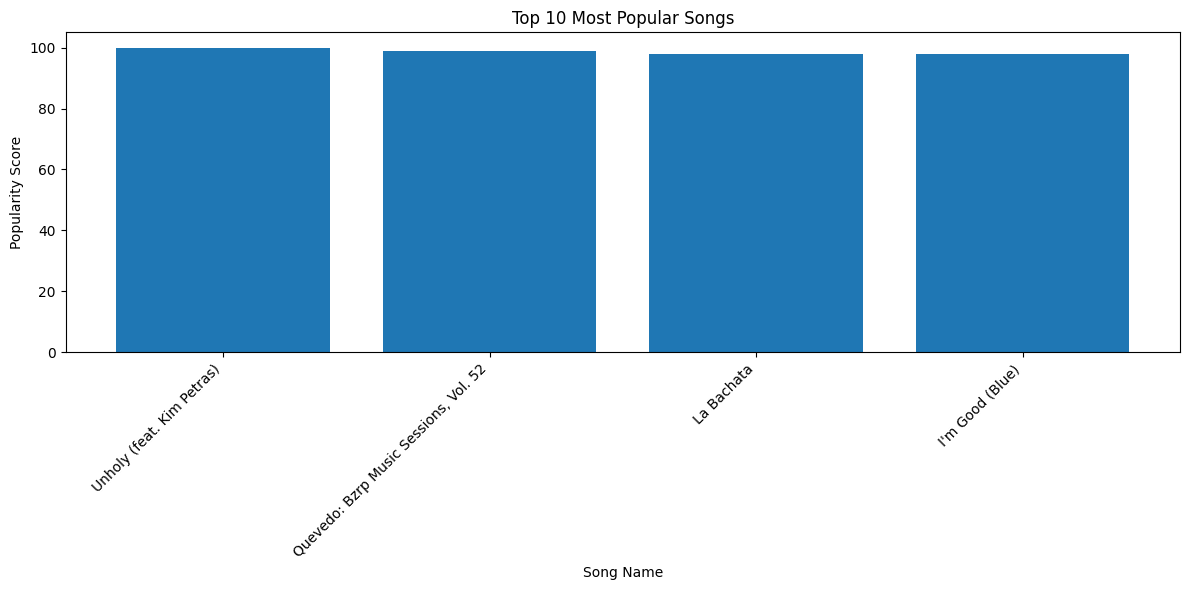

In [31]:
top_10 = df.sort_values(
    by='popularity',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

plt.bar(top_10['track_name'], top_10['popularity'])

plt.title('Top 10 Most Popular Songs')
plt.xlabel('Song Name')
plt.ylabel('Popularity Score')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

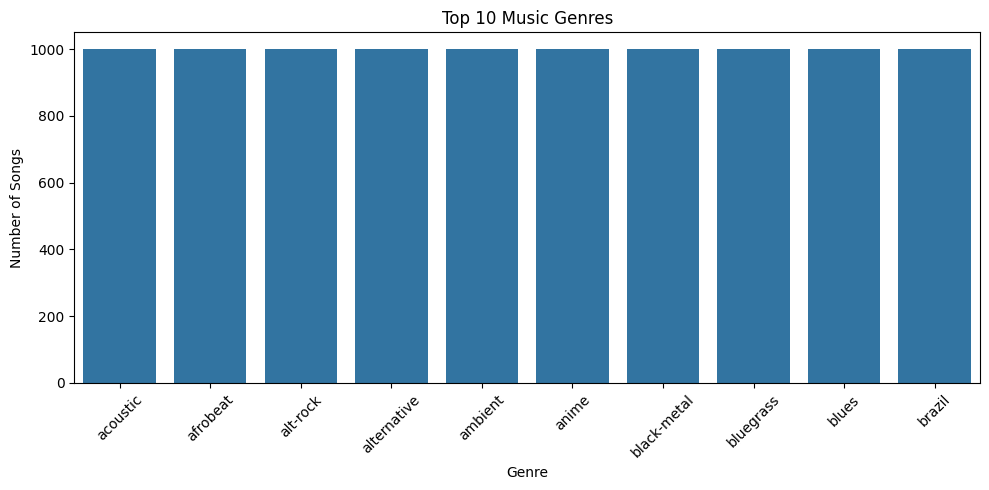

In [32]:
top_genres = df['track_genre'].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(x=top_genres.index, y=top_genres.values)

plt.title('Top 10 Music Genres')
plt.xlabel('Genre')
plt.ylabel('Number of Songs')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

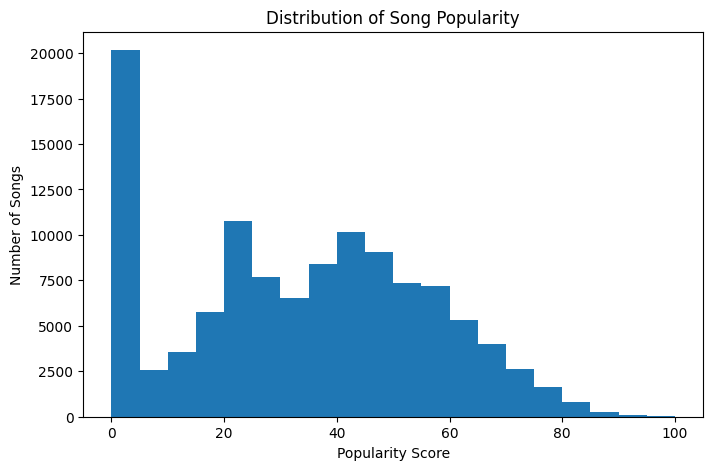

In [33]:
plt.figure(figsize=(8, 5))

plt.hist(df['popularity'], bins=20)

plt.title('Distribution of Song Popularity')
plt.xlabel('Popularity Score')
plt.ylabel('Number of Songs')

plt.show()

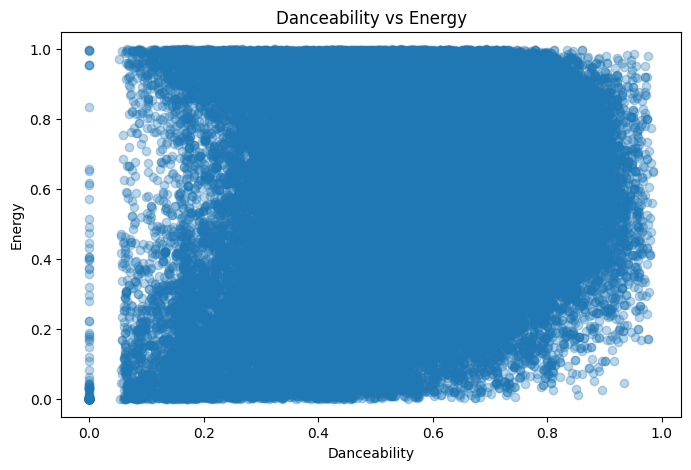

In [34]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['danceability'],
    df['energy'],
    alpha=0.3
)

plt.title('Danceability vs Energy')
plt.xlabel('Danceability')
plt.ylabel('Energy')

plt.show()

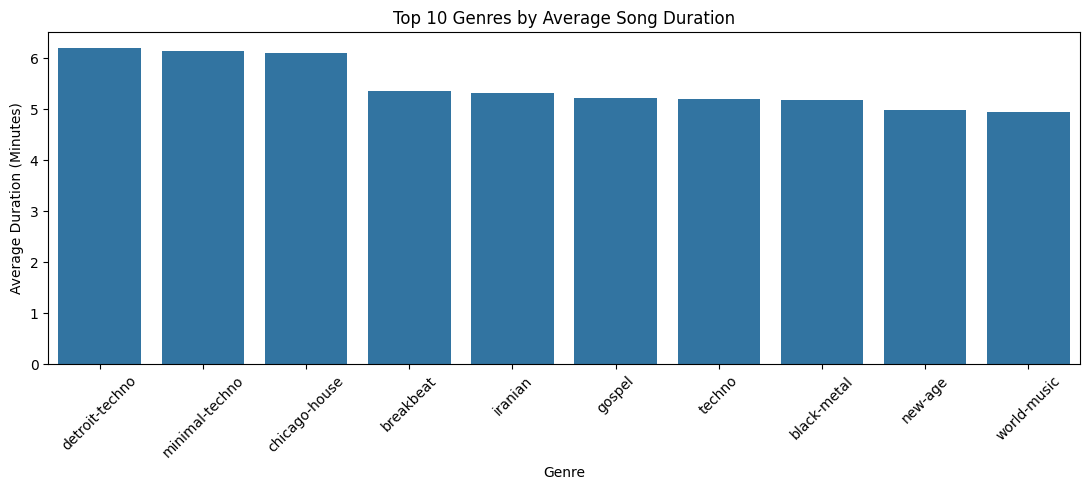

In [35]:
genre_duration = df.groupby(
    'track_genre'
)['duration_minutes'].mean().sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=genre_duration.index,
    y=genre_duration.values
)

plt.title('Top 10 Genres by Average Song Duration')
plt.xlabel('Genre')
plt.ylabel('Average Duration (Minutes)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
print("Final Dataset Shape:", df.shape)

print("Total Missing Values:", df.isnull().sum().sum())

print("\nFirst 5 Rows:")
display(df.head())

Final Dataset Shape: (114000, 21)
Total Missing Values: 0

First 5 Rows:


,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,...,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_minutes,popularity_level
0,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,...,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,3.844433,High
1,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,...,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,2.493500,Medium
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,...,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,3.513767,Medium
3,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,...,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,3.365550,High
4,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,...,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,3.314217,High



## Conclusion

In this project, the Spotify Tracks Dataset was analysed using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The dataset initially contained 114,000 records and 20 columns. Data cleaning was performed by handling missing text values and applying mean imputation to numerical columns wherever required. A new column, `duration_minutes`, was created to convert track duration from milliseconds into minutes. The unique `track_id` column was removed, and a new `popularity_level` column was added to classify songs as Low, Medium, or High popularity.

The analysis produced the following insights:

1. The average popularity score of the tracks is approximately **33.24**.
2. The average danceability is approximately **0.567**.
3. The average energy is approximately **0.641**.
4. Each of the 114 music genres contains 1,000 records, indicating a balanced dataset.
5. Detroit techno, minimal techno, and Chicago house have some of the highest average track durations.

Five visualizations were created to understand song popularity, music genres, danceability, energy, and average track duration.

Finally, the cleaned dataset contains **114,000 rows and 21 columns**, with **zero missing values**.

This project helped demonstrate how data cleaning, transformation, analysis, and visualization can be used to extract meaningful insights from a real-world music dataset.
